<div style="background: linear-gradient(90deg, #1c3d6e, #2e6db4); color: white; padding: 22px 26px; border-radius: 10px;">
<h1 style="color: white; margin-top: 0;">Airbnb Price Prediction System</h1>
<h3 style="color: #dbe8ff; margin: 0;">Assignment 03, Task 2</h3>
<p style="margin: 12px 0 0 0;"><b>Live App:</b> <a href="https://airbnb-price-fa24-bse-085.streamlit.app" style="color: white;">https://airbnb-price-fa24-bse-085.streamlit.app</a></p>
</div>

| | |
|:--|:--|
| **Student** | Muhammad Muneeb Shahzad |
| **Registration No.** | FA24-BSE-085 |
| **Course** | Machine Learning Fundamentals |
| **Instructor** | Respected Dr. Rao Muhammad Adeel Nawab |
| **Semester** | 5 |
| **Dataset used** | `airbnb_listings.xlsx` (Airbnb listings of Pakistani cities, full dataset, submitted with this notebook) |
| **Evaluation** | 10-Fold Cross Validation, Root Mean Squared Error (RMSE) |
| **Live App** | [https://airbnb-price-fa24-bse-085.streamlit.app](https://airbnb-price-fa24-bse-085.streamlit.app) |
| **GitHub Repo** | [https://github.com/VicegerentPrince/ml-lab-assignment-3](https://github.com/VicegerentPrince/ml-lab-assignment-3) |

## Introduction
This system predicts the price of one night at an Airbnb listing in Pakistan (in US dollars). It is a regression task. I followed the same steps as the Car Price Prediction notebook given by the instructor, but with a new dataset and 5 different algorithms.

**Dataset:** The Excel file has 1,118 Airbnb listings from Lahore, Islamabad, Karachi and Rawalpindi. The whole dataset is used.

**How to run on Google Colab:** Upload this notebook to [Google Colab](https://colab.research.google.com), click **Runtime > Run all** and upload `airbnb_listings.xlsx` when the **Choose Files** button appears in Step 2.1.

## Input and Output

### Inputs

| Input Attribute | Meaning | Possible Values |
|:--|:--|:--|
| **Guests** | Number of guests the listing allows | 1 to 16 |
| **Rating** | Guest rating of the listing (missing for new listings) | 1 to 5 |
| **Responserate** | How often the host replies to messages | 0 to 1 |
| **City** | City of the listing | Lahore, Islamabad, Karachi, Rawalpindi |
| **Roomtype** | Type of place | Entire place, Private room, Shared room |
| **Superhost** | Is the host a Superhost | Yes, No |
| **Responsetime** | How fast the host replies | within an hour, within a few hours, within a day, a few days or more, Unknown |
| **Identityverified** | Has Airbnb verified the host | Yes, No |

### Output

| Output Attribute | Meaning | Possible Values |
|:--|:--|:--|
| **Price_nightly** | Price of one night in US dollars | 10 to 97 |

## Algorithms
The Car Price system used Linear Regression, KNN, Decision Tree, Random Forest and Gradient Boosting. The assignment asks for different algorithms, so I used these 5:

| No. | Algorithm | How it works |
|:--|:--|:--|
| 1 | **Ridge Regression** | Linear Regression with a penalty that keeps the weights small |
| 2 | **Support Vector Regression (SVR)** | Fits a curve and ignores small errors inside a margin around it |
| 3 | **Extra Trees** | Many trees with random split points, the answer is the average of all trees |
| 4 | **AdaBoost** | Small trees trained one after another, each one focuses on the mistakes of the last |
| 5 | **Neural Network (MLP)** | A layer of 100 neurons that learns the weights over many rounds |

## 10-Fold Cross Validation
The data is split into 10 equal parts (folds). Each algorithm is trained on 9 folds and tested on the remaining fold. This is repeated 10 times so every fold is used for testing once. The final score is the average of the 10 rounds. All 5 algorithms are tested on the same folds, so the comparison is fair.

**RMSE** (Root Mean Squared Error) is in US dollars. It tells how far the predicted price is from the real price. Lower is better.

## Code

### Step 1: Import Libraries

In [1]:
import os
import time
import pickle

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from tqdm import tqdm

from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.dummy import DummyRegressor

# The 5 algorithms (none of them was used in the Car Price system)
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from sklearn.ensemble import ExtraTreesRegressor, AdaBoostRegressor
from sklearn.neural_network import MLPRegressor

pd.set_option("display.max_columns", None, "display.width", 200)

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)
print("scikit-learn version:", sklearn.__version__)
print("Matplotlib version:", matplotlib.__version__)

NumPy version: 2.2.6
Pandas version: 2.3.3
scikit-learn version: 1.7.2
Matplotlib version: 3.10.9


### Step 2: Load Sample Data

#### Step 2.1: Upload the Dataset (only needed on Google Colab)
On Colab a **Choose Files** button appears. Select `airbnb_listings.xlsx`. On my own computer the file is already in the same folder, so nothing is uploaded.

In [2]:
data_file = "airbnb_listings.xlsx"

try:
    from google.colab import files
    if not os.path.exists(data_file):
        uploaded = files.upload()
        os.rename(list(uploaded)[0], data_file)   # in case the browser renamed the file
except ImportError:
    pass   # not running on Colab

print("Dataset file found:", os.path.exists(data_file))

Dataset file found: True


#### Step 2.2: Read the Dataset
The Excel file has 3 sheets. The `Cleaned` sheet has all 1,118 listings with readable column names, so I used it. The `Rated` sheet only has the listings that have a rating, so it is not the full dataset.

In [3]:
print("Sheets in the Excel file:", pd.ExcelFile(data_file).sheet_names)

airbnb_data = pd.read_excel(data_file, sheet_name="Cleaned")

print("\n\nAirbnb Data (first 10 rows):")
print("============================\n")
print(airbnb_data.head(10))

Sheets in the Excel file: ['CombinedSemiCleaned', 'Cleaned', 'Rated']


Airbnb Data (first 10 rows):

                                         Listingname         Hostname                                              City       Roomtype Superhost  Price_nightly  Rating  Guests  Responserate  \
0                                               2020         Chaudhry                          Karachi, Sindh, Pakistan   Private room        No             23     NaN      16          0.22   
1        "2F3" Hotel Vista Inn DHA 1 F "5 Star look"  Muhammad Yaseen  Islamabad, Islamabad Capital Territory, Pakistan   Private room        No             25     NaN       2           NaN   
2    "La Casa de Versace" Versace themed apt in F10.             Arif  Islamabad, Islamabad Capital Territory, Pakistan   Entire place        No             63    4.63       4          0.92   
3        "LG1" Hotel Vista Inn DHA 1 F "5 Star look"  Muhammad Yaseen  Islamabad, Islamabad Capital Territory, Pakistan   Priv

### Step 3: Understand and Pre-process Sample Data

#### Step 3.1: Understand Sample Data

In [4]:
print("\n\nAttributes in Data:")
print("===================\n")
print(list(airbnb_data.columns))

print("\n\nNumber of Instances in Data:", len(airbnb_data))
print("================================\n")

print("\n\nMissing Values in each Attribute:")
print("=================================\n")
print(airbnb_data.isnull().sum())

print("\n\nPrice of One Night (US dollars):")
print("================================\n")
print(airbnb_data["Price_nightly"].describe().round(2))



Attributes in Data:

['Listingname', 'Hostname', 'City', 'Roomtype', 'Superhost', 'Price_nightly', 'Rating', 'Guests', 'Responserate', 'Responsetime', 'Identityverified']


Number of Instances in Data: 1118



Missing Values in each Attribute:

Listingname           0
Hostname              0
City                  0
Roomtype              0
Superhost             0
Price_nightly         0
Rating              780
Guests                0
Responserate        330
Responsetime        330
Identityverified      0
dtype: int64


Price of One Night (US dollars):

count    1118.00
mean       41.25
std        18.40
min        10.00
25%        25.00
50%        40.00
75%        54.75
max        97.00
Name: Price_nightly, dtype: float64


- **Rating** is missing for 780 listings. Airbnb only shows a rating after a few reviews, so these are mostly new listings.
- **Responserate** and **Responsetime** are missing for the same 330 listings, because Airbnb has no reply data for these hosts.
- Removing these rows would throw away most of the data, so they are kept. Missing numbers are filled with the median inside the pipeline in Step 5.
- Prices go from \$10 to \$97 and the average is about \$41. There are no extreme prices like the \$2,000,000 cars in the Car Price data.

#### Step 3.2: Pre-process Sample Data
- Repeated rows are removed, so the same listing is never in the training folds and the testing fold at the same time
- `City` has values like "Lahore, Punjab, Pakistan", so only the city name is kept
- Some room types have an extra space at the end ("Private room " and "Private room"), so the spaces are removed
- Missing `Responsetime` is changed to "Unknown", because it means Airbnb has no reply data for that host

In [5]:
airbnb_data = airbnb_data.drop_duplicates().reset_index(drop=True)

airbnb_data["City"] = airbnb_data["City"].str.split(",").str[0].str.strip()
airbnb_data["Roomtype"] = airbnb_data["Roomtype"].str.strip()
airbnb_data["Responsetime"] = airbnb_data["Responsetime"].fillna("Unknown")

print("Number of listings after removing repeated rows:", len(airbnb_data))
print("\nCities:", sorted(airbnb_data["City"].unique()))
print("Room types:", sorted(airbnb_data["Roomtype"].unique()))
print("Response times:", sorted(airbnb_data["Responsetime"].unique()))

Number of listings after removing repeated rows: 1118

Cities: ['Islamabad', 'Karachi', 'Lahore', 'Rawalpindi']
Room types: ['Entire place', 'Private room', 'Shared room']
Response times: ['Unknown', 'a few days or more', 'within a day', 'within a few hours', 'within an hour']


### Step 4: Feature Extraction
- 8 input attributes are used: 3 numbers (Guests, Rating, Responserate) and 5 text values (City, Roomtype, Superhost, Responsetime, Identityverified)
- `Listingname` and `Hostname` are not used, because they are different for almost every listing and the model cannot learn a pattern from them
- The tables below show the average price for each city and room type

In [6]:
print("Average Price by City:")
print("======================\n")
print(airbnb_data.groupby("City")["Price_nightly"].agg(["count", "mean"]).round(2), "\n")

print("Average Price by Room Type:")
print("===========================\n")
print(airbnb_data.groupby("Roomtype")["Price_nightly"].agg(["count", "mean"]).round(2), "\n")

print("Correlation of the Number Attributes with Price:")
print("================================================\n")
print(airbnb_data[["Guests", "Rating", "Responserate", "Price_nightly"]].corr()["Price_nightly"].round(2))

Average Price by City:

            count   mean
City                    
Islamabad     306  49.22
Karachi       269  42.80
Lahore        461  33.32
Rawalpindi     82  51.04 

Average Price by Room Type:

              count   mean
Roomtype                  
Entire place    480  47.71
Private room    617  36.63
Shared room      21  29.62 

Correlation of the Number Attributes with Price:

Guests           0.16
Rating           0.04
Responserate     0.10
Price_nightly    1.00
Name: Price_nightly, dtype: float64


In [7]:
numeric_features = ["Guests", "Rating", "Responserate"]
categorical_features = ["City", "Roomtype", "Superhost", "Responsetime", "Identityverified"]

X = airbnb_data[numeric_features + categorical_features]   # inputs
y = airbnb_data["Price_nightly"]                            # output

print("Inputs (X):", X.shape)
print("Output (y):", y.shape)

Inputs (X): (1118, 8)
Output (y): (1118,)


### Step 5: Build the Pre-processing Pipeline
- **Numbers:** missing values are filled with the median, then scaled so that Guests (1 to 16) does not matter more than Responserate (0 to 1). Ridge, SVR and the Neural Network need scaled inputs.
- **Text:** one-hot encoding makes one 0/1 column for each value. Label encoding would give Lahore = 2 and Rawalpindi = 3, which makes it look like one city is bigger than another.
- The pipeline is trained again inside every fold, using only the training folds. This way the testing fold is never seen during training.

In [8]:
numeric_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
])

categorical_steps = Pipeline([
    ("fill_missing", SimpleImputer(strategy="most_frequent")),
    ("one_hot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("numbers", numeric_steps, numeric_features),
    ("text", categorical_steps, categorical_features),
])

preprocessor

,transformers,"[('numbers', ...), ('text', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


### Step 6: Define the 5 Regression Algorithms
Default settings are used. The Neural Network gets `max_iter=3000`, because with the default of 200 rounds it stops before it finishes learning and shows a warning. `random_state=42` gives the same result every time the notebook is run.

In [9]:
algorithms = {
    "Ridge Regression": Ridge(),
    "SVR": SVR(),
    "Extra Trees": ExtraTreesRegressor(random_state=42),
    "AdaBoost": AdaBoostRegressor(random_state=42),
    "Neural Network (MLP)": MLPRegressor(max_iter=3000, random_state=42),
}

for number, name in enumerate(algorithms, 1):
    print(number, name)

1 Ridge Regression
2 SVR
3 Extra Trees
4 AdaBoost
5 Neural Network (MLP)


### Step 7: Set Up 10-Fold Cross Validation
`shuffle=True` mixes the listings before splitting, because the file is sorted by listing name. `random_state=42` makes sure all 5 algorithms get the same 10 folds.

In [10]:
K = 10
kfold = KFold(n_splits=K, shuffle=True, random_state=42)

for fold_number, (train_index, test_index) in enumerate(kfold.split(X), 1):
    print(f"Fold {fold_number}: training listings = {len(train_index)}, testing listings = {len(test_index)}")

Fold 1: training listings = 1006, testing listings = 112
Fold 2: training listings = 1006, testing listings = 112
Fold 3: training listings = 1006, testing listings = 112
Fold 4: training listings = 1006, testing listings = 112
Fold 5: training listings = 1006, testing listings = 112
Fold 6: training listings = 1006, testing listings = 112
Fold 7: training listings = 1006, testing listings = 112
Fold 8: training listings = 1006, testing listings = 112
Fold 9: training listings = 1007, testing listings = 111
Fold 10: training listings = 1007, testing listings = 111


### Step 8: Run 10-Fold Cross Validation for All 5 Algorithms
For every algorithm and every fold:
1. Make a new untrained copy of the pipeline and the algorithm
2. Train it on the 9 training folds
3. Predict the prices of the testing fold
4. Calculate RMSE, MAE and R² on the testing fold, and RMSE on the training folds

The progress bar shows how many of the 50 steps (5 algorithms x 10 folds) are done, the time spent and the time remaining.

In [11]:
results = []      # one row for each algorithm
fold_rmse = {}    # RMSE of each fold for each algorithm

progress_bar = tqdm(total=len(algorithms) * K, unit="fold")

for name, algorithm in algorithms.items():
    progress_bar.set_description(name)
    rmse_list, mae_list, r2_list, train_rmse_list = [], [], [], []
    start_time = time.time()

    for train_index, test_index in kfold.split(X):
        X_train, X_test = X.iloc[train_index], X.iloc[test_index]
        y_train, y_test = y.iloc[train_index], y.iloc[test_index]

        model = Pipeline([("preprocessor", clone(preprocessor)), ("regressor", clone(algorithm))])
        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        rmse_list.append(np.sqrt(mean_squared_error(y_test, predictions)))
        mae_list.append(mean_absolute_error(y_test, predictions))
        r2_list.append(r2_score(y_test, predictions))
        train_rmse_list.append(np.sqrt(mean_squared_error(y_train, model.predict(X_train))))

        progress_bar.update(1)

    fold_rmse[name] = rmse_list
    results.append({
        "Algorithm": name,
        "Mean RMSE": np.mean(rmse_list),
        "Std RMSE": np.std(rmse_list),
        "Mean MAE": np.mean(mae_list),
        "Mean R2": np.mean(r2_list),
        "Train RMSE": np.mean(train_rmse_list),
        "Time (s)": time.time() - start_time,
    })

progress_bar.close()
print("10-fold cross validation finished for all 5 algorithms")

Neural Network (MLP): 100%|██████████| 50/50 [00:12<00:00,  3.91fold/s]


10-fold cross validation finished for all 5 algorithms


### Step 9: Compare the Algorithms

#### Step 9.1: RMSE of Each Algorithm on Each Fold
Each row is one fold and each column is one algorithm. The last table counts how many folds each algorithm won (had the lowest RMSE).

In [12]:
fold_table = pd.DataFrame(fold_rmse, index=[f"Fold {i}" for i in range(1, K + 1)])

print("RMSE on Each Fold (US dollars):")
print("===============================\n")
print(fold_table.round(2))

print("\n\nNumber of Folds Won by Each Algorithm:")
print("======================================\n")
print(fold_table.idxmin(axis=1).value_counts())

RMSE on Each Fold (US dollars):

         Ridge Regression    SVR  Extra Trees  AdaBoost  Neural Network (MLP)
Fold 1              14.73  15.13        15.65     15.13                 13.79
Fold 2              16.01  15.68        16.86     16.24                 14.57
Fold 3              16.19  16.19        16.35     15.37                 14.88
Fold 4              16.02  16.03        19.16     15.47                 15.91
Fold 5              14.08  14.16        16.48     14.06                 13.08
Fold 6              17.15  17.08        17.60     16.85                 16.40
Fold 7              15.40  15.21        16.12     15.10                 14.33
Fold 8              15.75  16.08        17.65     15.37                 15.10
Fold 9              16.75  17.51        18.59     16.87                 16.86
Fold 10             15.88  15.30        18.43     15.71                 15.38


Number of Folds Won by Each Algorithm:

Neural Network (MLP)    7
AdaBoost                1
Ridge Regressio

#### Step 9.2: Summary Table
- **Mean RMSE:** average RMSE of the 10 folds, used to rank the algorithms (lower is better)
- **Std RMSE:** how much the RMSE changes from fold to fold (lower means more stable)
- **Mean MAE:** average size of a mistake in dollars (lower is better)
- **Mean R2:** how much of the price change the model explains (1 is perfect, higher is better)
- **Train RMSE:** RMSE on the training folds. If it is much lower than Mean RMSE, the model memorized the training data (overfitting)

In [13]:
summary = pd.DataFrame(results).sort_values("Mean RMSE").reset_index(drop=True)
summary.insert(0, "Rank", range(1, len(summary) + 1))

summary.round(2)

,Rank,Algorithm,Mean RMSE,Std RMSE,Mean MAE,Mean R2,Train RMSE,Time (s)
0,1,Neural Network (MLP),15.03,1.10,12.04,0.33,14.34,9.72
1,2,AdaBoost,15.62,0.81,12.89,0.27,15.24,0.34
2,3,Ridge Regression,15.80,0.85,12.84,0.26,15.60,0.15
3,4,SVR,15.84,0.93,12.60,0.25,15.58,0.81
4,5,Extra Trees,17.29,1.12,13.34,0.11,9.01,1.77


#### Step 9.3: Charts

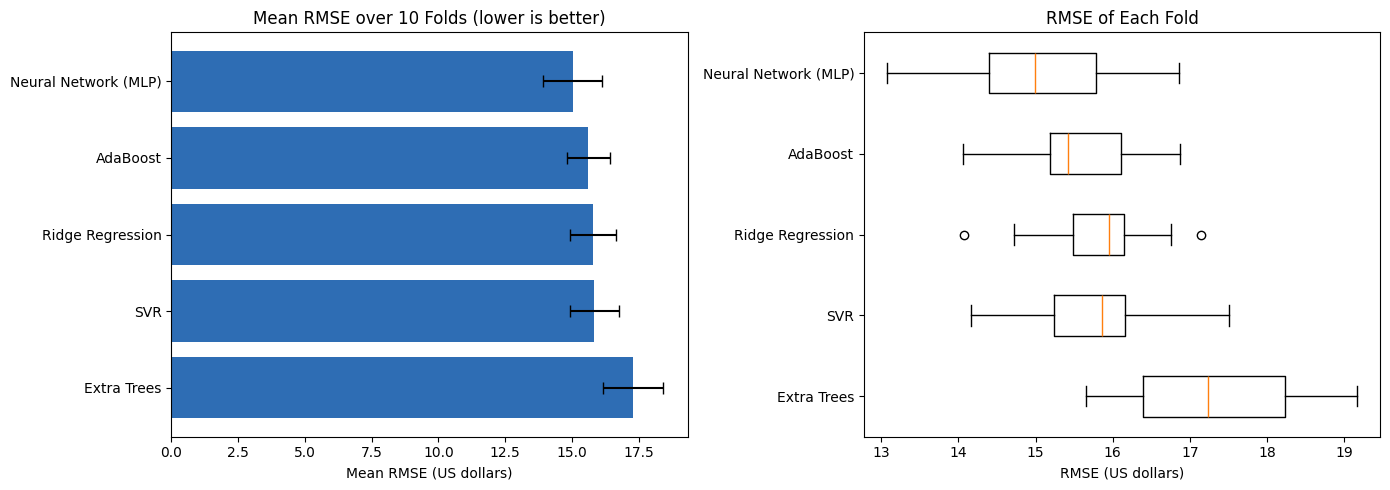

In [14]:
fig, (left_chart, right_chart) = plt.subplots(1, 2, figsize=(14, 5))

# Left: mean RMSE of each algorithm, the black line shows the standard deviation
left_chart.barh(summary["Algorithm"], summary["Mean RMSE"], xerr=summary["Std RMSE"], color="#2e6db4", capsize=4)
left_chart.invert_yaxis()
left_chart.set_xlabel("Mean RMSE (US dollars)")
left_chart.set_title("Mean RMSE over 10 Folds (lower is better)")

# Right: RMSE of every fold, to see how much each algorithm changes between folds
right_chart.boxplot([fold_rmse[name] for name in summary["Algorithm"]], orientation="horizontal")
right_chart.set_yticklabels(summary["Algorithm"])
right_chart.invert_yaxis()
right_chart.set_xlabel("RMSE (US dollars)")
right_chart.set_title("RMSE of Each Fold")

plt.tight_layout()
plt.show()

#### Step 9.4: Compare With a Simple Baseline
The baseline always predicts the average price of the training folds and ignores all inputs. A useful model must have a lower RMSE than this. The same 10 folds are used.

In [15]:
baseline_rmse_list = []
for train_index, test_index in kfold.split(X):
    baseline = DummyRegressor(strategy="mean")
    baseline.fit(X.iloc[train_index], y.iloc[train_index])
    predictions = baseline.predict(X.iloc[test_index])
    baseline_rmse_list.append(np.sqrt(mean_squared_error(y.iloc[test_index], predictions)))

baseline_rmse = np.mean(baseline_rmse_list)
print(f"Baseline (always predict the average price): RMSE = ${baseline_rmse:.2f}\n")

for index, row in summary.iterrows():
    improvement = (1 - row["Mean RMSE"] / baseline_rmse) * 100
    print(f"{row['Algorithm']:<22} RMSE = ${row['Mean RMSE']:.2f}   {improvement:.1f}% lower than the baseline")

Baseline (always predict the average price): RMSE = $18.40

Neural Network (MLP)   RMSE = $15.03   18.3% lower than the baseline
AdaBoost               RMSE = $15.62   15.1% lower than the baseline
Ridge Regression       RMSE = $15.80   14.1% lower than the baseline
SVR                    RMSE = $15.84   13.9% lower than the baseline
Extra Trees            RMSE = $17.29   6.0% lower than the baseline


#### Step 9.5: Observations

1. The **Neural Network (MLP)** has the lowest mean RMSE (\$15.03) and won 7 of the 10 folds. AdaBoost is second (\$15.62), then Ridge Regression (\$15.80) and SVR (\$15.84).
2. The top 4 algorithms are close. The difference between 1st and 4th place (\$0.81) is smaller than their standard deviation over the folds, so the Neural Network is the best but not by much.
3. **Extra Trees** is the worst (\$17.29) because it overfits. Its RMSE on the training folds is only \$9.01 but on the testing fold it is \$17.29. The trees memorized the training prices instead of learning a general pattern. For the other 4 algorithms the training and testing RMSE are almost the same.
4. All 5 algorithms beat the baseline (\$18.40). The Neural Network has 18.3% lower error than the baseline.
5. R2 is low for all algorithms (best is 0.33). The 8 inputs explain only about one third of the price changes. Important things like the exact area, number of bedrooms and amenities are not in the dataset.
6. AdaBoost has the smallest standard deviation (\$0.81), so it is the most stable from fold to fold.
7. The Neural Network is the slowest (about 9 seconds for 10 folds) and Ridge Regression is the fastest (less than 1 second). On this dataset both are fast enough, so the most accurate one is selected.

### Step 10: Execute the Training Phase

#### Step 10.1: Train the Best Algorithm on All the Data
Cross validation was only used to choose the best algorithm. Now the best algorithm is trained again on all 1,118 listings. The cross validation RMSE is the estimate of how well it will do on new listings.

In [16]:
best_algorithm = summary.loc[0, "Algorithm"]
best_rmse = summary.loc[0, "Mean RMSE"]

final_model = Pipeline([("preprocessor", preprocessor), ("regressor", algorithms[best_algorithm])])
final_model.fit(X, y)

print("Best algorithm:", best_algorithm)
print(f"Expected RMSE on new listings: ${best_rmse:.2f}")
print("Trained on", len(X), "listings")

Best algorithm: Neural Network (MLP)
Expected RMSE on new listings: $15.03
Trained on 1118 listings


#### Step 10.2: Save the Trained Model
The saved file has the whole pipeline (filling missing values, scaling, one-hot encoding and the algorithm), so it can predict directly from the raw inputs. The web app uses this file.

In [17]:
with open("airbnb_price_model.pkl", "wb") as file:
    pickle.dump(final_model, file)

print("Saved: airbnb_price_model.pkl")

Saved: airbnb_price_model.pkl


### Step 11: Execute the Application Phase

#### Step 11.1: Take Input from User

In [18]:
# Details of a new listing (change these values to test another listing)
guests_input = 4
rating_input = 4.8
response_rate_input = 0.95
city_input = "Islamabad"
room_type_input = "Entire place"
superhost_input = "No"
response_time_input = "within an hour"
identity_verified_input = "Yes"

#### Step 11.2: Convert User Input into Feature Vector (Exactly Same as Feature Vectors of Sample Data)

In [19]:
user_input = pd.DataFrame({
    "Guests": [guests_input],
    "Rating": [rating_input],
    "Responserate": [response_rate_input],
    "City": [city_input],
    "Roomtype": [room_type_input],
    "Superhost": [superhost_input],
    "Responsetime": [response_time_input],
    "Identityverified": [identity_verified_input],
})

print("\n\nUser Input Feature Vector:")
print("==========================\n")
print(user_input)



User Input Feature Vector:

   Guests  Rating  Responserate       City      Roomtype Superhost    Responsetime Identityverified
0       4     4.8          0.95  Islamabad  Entire place        No  within an hour              Yes


#### Step 11.3: Load the Saved Model

In [20]:
with open("airbnb_price_model.pkl", "rb") as file:
    model = pickle.load(file)

print("Model loaded from airbnb_price_model.pkl")

Model loaded from airbnb_price_model.pkl


#### Step 11.4: Model Prediction
No encoding is needed here, because the saved pipeline fills, scales and one-hot encodes the input by itself.

In [21]:
predicted_price = model.predict(user_input)[0]

print(f"Predicted price of one night: ${predicted_price:.2f}")
print(f"Usual error of this model: about ${best_rmse:.2f}")

Predicted price of one night: $53.18
Usual error of this model: about $15.03


### Step 12: Execute the Feedback Phase

#### Step 12.1: Collect Feedback from Users and Domain Experts on Performance of the Model Deployed in the Real World

In [22]:
feedback = [
    "Islamabad, Entire place, 4 guests, rating 4.8 was predicted $53.18. The average Entire place in Islamabad is in this range.",
    "Lahore, Private room, 2 guests, no rating was predicted $35.75. The average Private room in Lahore costs $30.71, so the model is a bit high for this one.",
    "The usual error is about $15 on an average price of $41, so the price should be used as a rough guide only.",
    "No Airbnb host or property manager has checked the predictions yet.",
]

for number, item in enumerate(feedback, 1):
    print(number, item)

1 Islamabad, Entire place, 4 guests, rating 4.8 was predicted $53.18. The average Entire place in Islamabad is in this range.
2 Lahore, Private room, 2 guests, no rating was predicted $35.75. The average Private room in Lahore costs $30.71, so the model is a bit high for this one.
3 The usual error is about $15 on an average price of $41, so the price should be used as a rough guide only.
4 No Airbnb host or property manager has checked the predictions yet.


#### Step 12.2: Make a List of Potential Improvements

In [23]:
improvements = [
    "Add more inputs like the area of the city (DHA, Gulberg, F-7), number of bedrooms and amenities",
    "Tune the settings of the best algorithms with GridSearchCV",
    "Collect more listings, more cities and listings above $100 per night",
    "Show the price in Pakistani rupees in the web app",
]

for number, item in enumerate(improvements, 1):
    print(number, item)

1 Add more inputs like the area of the city (DHA, Gulberg, F-7), number of bedrooms and amenities
2 Tune the settings of the best algorithms with GridSearchCV
3 Collect more listings, more cities and listings above $100 per night
4 Show the price in Pakistani rupees in the web app


#### Step 12.3: Improve the Model Based on Feedback

In [24]:
print("Next version: add more inputs and tune the best algorithm, run 10-fold cross validation again, then replace airbnb_price_model.pkl if the RMSE is lower")

Next version: add more inputs and tune the best algorithm, run 10-fold cross validation again, then replace airbnb_price_model.pkl if the RMSE is lower


### Step 13: Deploy the Model on the Cloud
- The trained model is deployed on Streamlit Community Cloud
- `app.py` loads `airbnb_price_model.pkl`, takes the 8 inputs from the user and shows the predicted price
- `requirements.txt` has the libraries needed by the app, with the same scikit-learn version used to train the model
- **Live App:** [https://airbnb-price-fa24-bse-085.streamlit.app](https://airbnb-price-fa24-bse-085.streamlit.app)
- **GitHub Repo:** [https://github.com/VicegerentPrince/ml-lab-assignment-3](https://github.com/VicegerentPrince/ml-lab-assignment-3)

## Conclusion

I compared 5 algorithms that were not used in the Car Price system on the full Airbnb dataset (1,118 listings) using 10-fold cross validation.

| Rank | Algorithm | Mean RMSE | Mean MAE | Mean R2 |
|:--|:--|:--|:--|:--|
| 1 | Neural Network (MLP) | \$15.03 | \$12.04 | 0.33 |
| 2 | AdaBoost | \$15.62 | \$12.89 | 0.27 |
| 3 | Ridge Regression | \$15.80 | \$12.84 | 0.26 |
| 4 | SVR | \$15.84 | \$12.60 | 0.25 |
| 5 | Extra Trees | \$17.29 | \$13.34 | 0.11 |
| - | Baseline (always the average price) | \$18.40 | | |

The Neural Network had the lowest error, so it was trained on all the listings, saved, and deployed as a web app on Streamlit Community Cloud. Extra Trees overfit the training data. City and room type affect the price the most. Adding more inputs like the area and number of bedrooms would help more than changing the algorithm.

In the Car Price data the tree based algorithms did best, because car prices have very large jumps for luxury cars. Airbnb prices stay between \$10 and \$97, so the smoother models (Neural Network, Ridge, SVR) did well. This shows that the best algorithm depends on the data, which is why several algorithms are compared with cross validation.

---
<p style="text-align:center; color: gray;">Muhammad Muneeb Shahzad | FA24-BSE-085 | AIC354 Machine Learning Fundamentals | Fall 2026</p>